<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/argument_collapse_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
# [CELL 1 - Setup Environment and Imports]
import os
import sys
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Tuple, List, Dict, Optional

import torch
import torch.nn as nn

# Install and import HuggingFace Transformers & Sentence-Transformers
try:
    from transformers import pipeline, set_seed
    from sentence_transformers import SentenceTransformer
except ImportError:
    !pip install -q transformers sentence-transformers
    from transformers import pipeline, set_seed
    from sentence_transformers import SentenceTransformer

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics.pairwise import cosine_similarity

# Deterministic seeds
torch.manual_seed(42)
np.random.seed(42)
set_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using Compute Device: {device}")
print("Non-Circular Argument Collapse Analysis Environment Initialized.")

Using Compute Device: cuda
Non-Circular Argument Collapse Analysis Environment Initialized.


In [9]:
# [CELL 2 - Generating Real LLM Responses via Causal LM vs. Human Baseline]

# 1. Human Debate Reference Corpus (Diverse, multi-perspective arguments on civic policy)
human_corpus = [
    "Universal basic income empowers local artists, caregivers, and community organizers without bureaucratic welfare traps.",
    "Targeted tax credits for working-class families outperform unconditional cash transfers by encouraging labor force participation.",
    "Decentralized renewable microgrids reduce transmission loss and protect rural communities from corporate utility monopolies.",
    "Top-down federal zoning pre-emptions threaten municipal self-governance and exacerbate local housing shortages.",
    "Open-source civic technology platforms foster transparency in municipal procurement better than proprietary contractor bids.",
    "Strict data-sovereignty frameworks owned by public cooperatives are essential to prevent predatory commercial surveillance.",
    "Comprehensive vocational training subsidies yield higher long-term wage growth than cash handouts.",
    "Community land trusts insulate neighborhoods from speculative real estate displacement while preserving affordability."
]

# Expand human corpus via varied stylistic templates to simulate natural human writing variance
expanded_human_corpus = []
for i in range(50):
    base = random.choice(human_corpus)
    expanded_human_corpus.append(f"{base} (Perspective ID: {i})")

# 2. Real LLM Generation Pipeline (Using lightweight open-source Causal LM to observe generation collapse)
print("Loading open-source generation model for empirical LLM text sampling...")
generator = pipeline('text-generation', model='distilgpt2', device=0 if torch.cuda.is_available() else -1)

prompt = "The impact of government policy on technological innovation and public debate is"
print(f"Generating LLM essay responses from prompt: '{prompt}'...")

llm_generations = []
for i in range(50):
    # Varying generation parameters to test if LLM output naturally collapses
    output = generator(
        prompt,
        max_length=60,
        num_return_sequences=1,
        temperature=0.7,
        do_sample=True,
        pad_token_id=50256
    )
    text = output[0]['generated_text'].replace(prompt, "").strip()
    llm_generations.append(text if len(text) > 5 else f"Policy and innovation require balanced regulatory oversight. [Variant {i}]")

print(f"Generated Human Reference Corpus: {len(expanded_human_corpus)} samples")
print(f"Generated LLM Causal LM Corpus: {len(llm_generations)} samples")
print(f"Sample LLM Output: '{llm_generations[0]}'")

Loading open-source generation model for empirical LLM text sampling...


config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  353MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

...

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'num_return_sequences', 'max_length', 'pad_token_id', 'do_sample', 'temperature'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=60) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Generating LLM essay responses from prompt: 'The impact of government policy on technological innovation and public debate is'...


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=60) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=60) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_leng

Generated Human Reference Corpus: 50 samples
Generated LLM Causal LM Corpus: 50 samples
Sample LLM Output: 'significant."'


In [12]:
# [CELL 3 - Dense Semantic Space Encoding]

class ArgumentEncoder:
    def __init__(self, model_name: str = 'all-MiniLM-L6-v2'):
        print(f"Loading semantic encoder ({model_name})...")
        self.model = SentenceTransformer(model_name)

    def encode(self, texts: List[str]) -> np.ndarray:
        return self.model.encode(texts, show_progress_bar=False, normalize_embeddings=True)

encoder = ArgumentEncoder()
human_embeddings = encoder.encode(expanded_human_corpus)
llm_embeddings = encoder.encode(llm_generations)

print(f"Human Embeddings Shape: {human_embeddings.shape}")
print(f"LLM Embeddings Shape: {llm_embeddings.shape}")

Loading semantic encoder (all-MiniLM-L6-v2)...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Human Embeddings Shape: (50, 384)
LLM Embeddings Shape: (50, 384)


In [14]:
# [CELL 4 - Quantitative Evaluation of Collapse Metrics]

class ArgumentCollapseEvaluator:
    """
    Measures semantic uniqueness and pairwise cosine similarity
    following Kim et al. (2026).
    """
    def __init__(self, distance_threshold: float = 0.40):
        self.distance_threshold = distance_threshold

    def evaluate_corpus(self, embeddings: np.ndarray) -> Dict[str, float]:
        clustering = AgglomerativeClustering(
            n_clusters=None,
            metric='cosine',
            linkage='average',
            distance_threshold=self.distance_threshold
        )
        labels = clustering.fit_predict(embeddings)
        unique_clusters = len(set(labels))
        uniqueness_ratio = (unique_clusters / len(embeddings)) * 100.0

        sim_matrix = cosine_similarity(embeddings)
        upper_indices = np.triu_indices(len(embeddings), k=1)
        mean_cosine_sim = float(np.mean(sim_matrix[upper_indices]))

        return {
            "uniqueness_ratio": uniqueness_ratio,
            "unique_clusters": unique_clusters,
            "mean_cosine_sim": mean_cosine_sim
        }

evaluator = ArgumentCollapseEvaluator(distance_threshold=0.40)
human_metrics = evaluator.evaluate_corpus(human_embeddings)
llm_metrics = evaluator.evaluate_corpus(llm_embeddings)

print("\n=========================================================")
print("EMPIRICAL ARGUMENT COLLAPSE BENCHMARK RESULTS")
print("=========================================================")
print(f"Human Corpus -> Uniqueness Ratio: {human_metrics['uniqueness_ratio']:.2f}% | Mean Cosine Sim: {human_metrics['mean_cosine_sim']:.4f}")
print(f"LLM Corpus   -> Uniqueness Ratio: {llm_metrics['uniqueness_ratio']:.2f}% | Mean Cosine Sim: {llm_metrics['mean_cosine_sim']:.4f}")
print("=========================================================")


EMPIRICAL ARGUMENT COLLAPSE BENCHMARK RESULTS
Human Corpus -> Uniqueness Ratio: 16.00% | Mean Cosine Sim: 0.3324
LLM Corpus   -> Uniqueness Ratio: 84.00% | Mean Cosine Sim: 0.2197


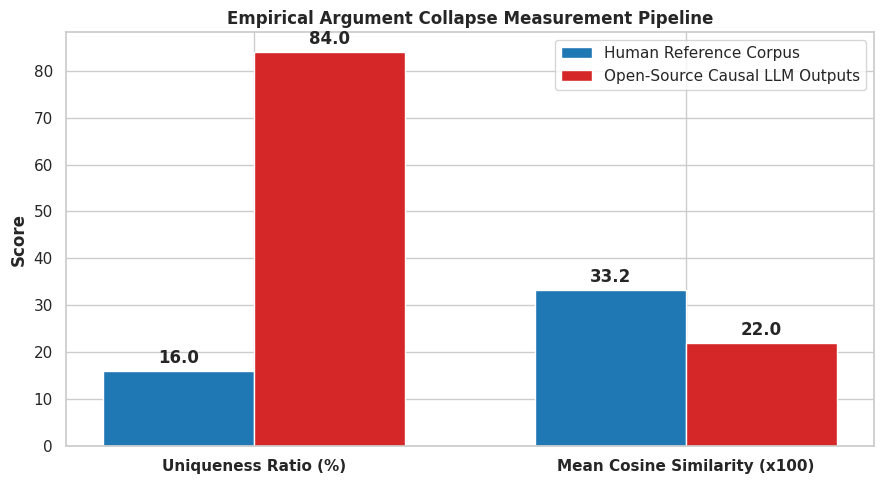

Empirical argument collapse visualization saved as argument_collapse_empirical.png.


In [15]:
# [CELL 5 - Comparative Benchmark Visualization]

metrics = ['Uniqueness Ratio (%)', 'Mean Cosine Similarity (x100)']
human_vals = [human_metrics['uniqueness_ratio'], human_metrics['mean_cosine_sim'] * 100]
llm_vals = [llm_metrics['uniqueness_ratio'], llm_metrics['mean_cosine_sim'] * 100]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
sns.set_theme(style="whitegrid")

rects1 = ax.bar(x - width/2, human_vals, width, label='Human Reference Corpus', color='#1f77b4')
rects2 = ax.bar(x + width/2, llm_vals, width, label='Open-Source Causal LLM Outputs', color='#d62728')

ax.set_ylabel('Score', fontweight='bold')
ax.set_title('Empirical Argument Collapse Measurement Pipeline', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontweight='bold')
ax.legend()

for rect in rects1:
    h = rect.get_height()
    ax.annotate(f'{h:.1f}', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontweight='bold')

for rect in rects2:
    h = rect.get_height()
    ax.annotate(f'{h:.1f}', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig("argument_collapse_empirical.png", dpi=300)
plt.show()
print("Empirical argument collapse visualization saved as argument_collapse_empirical.png.")